In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from ml3_03_data_split_methods_jacquieb import split_by_date_ratio_train_validation_test
import ml3_03_split_visualization_jacquieb

from sklearn.preprocessing import StandardScaler

In [117]:
DF_path = r'data\train_df_processed_full.csv'
df = pd.read_csv(DF_path)
# df.shape
df.head(2)

,bathrooms,bedrooms,price,interest,created,Elevator,HardwoodFloors,CatsAllowed,DogsAllowed,Doorman,...,Pre-War,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,NewConstruction,Terrace
0,1.0,1,2400,1,2016-06-16 05:55:27,0,1,1,1,0,...,1,0,0,0,1,0,0,0,0,0
1,1.0,2,3800,0,2016-06-01 05:44:33,1,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0


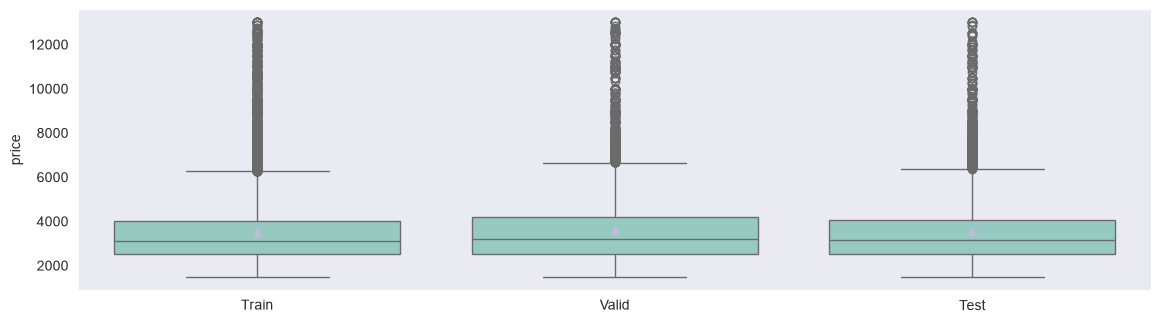

Размер df_train =  (29027, 24) 								 Размер df_valid = (9676, 24) 								 Размер df_test = (9676, 24)


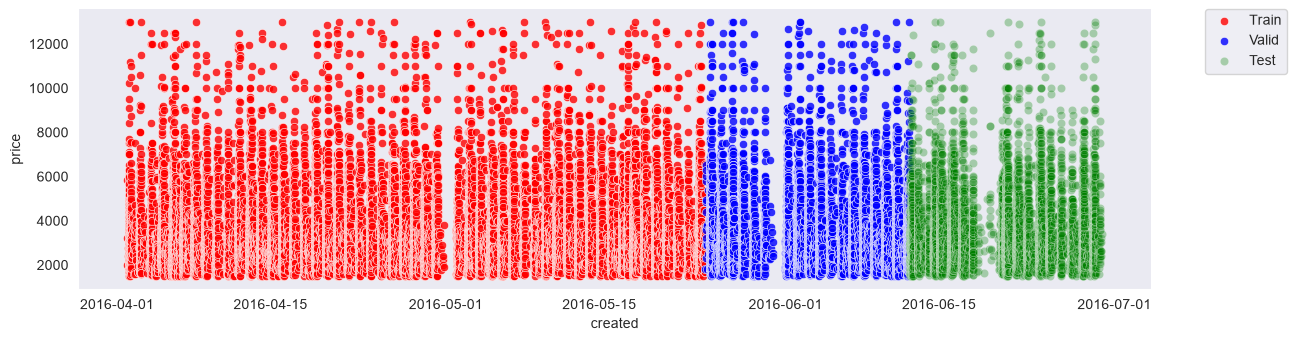

In [118]:
df_train, df_valid, df_test = split_by_date_ratio_train_validation_test(df, validation_size=0.2, test_size=0.2,
                                                                        date_field='created',
                                                                        )
ml3_03_split_visualization_jacquieb.visualize_train_valid_test_split(df_train, df_valid, df_test)

In [119]:
features = [col for col in df.columns if col not in ['created', 'price',
                                                     # 'interest'
                                                     ]]
X_train, y_train = df_train[features], df_train['price']
X_val, y_val = df_valid[features], df_valid['price']
X_test, y_test = df_test[features], df_test['price']
# --------------------------------------------------------------------------
# scaler = StandardScaler()
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
# Трансформируем валидацию и тест, используя параметры (mean, std) из трейна
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
# --------------------------------------------------------------------------
best_alpha = 20
final_lasso = Lasso(alpha=best_alpha, max_iter=10000, random_state=21)
final_lasso.fit(X_train_scaled, y_train)
y_test_pred = final_lasso.predict(X_test_scaled)
# Считаем метрики
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("\n--- Финальные метрики на Test set ---")
print('alpha = ',best_alpha)
print(f"MSE:  {test_mse:.18f}")
print(f"RMSE: {test_rmse:.18f}") # <-- ДОБАВЛЕНО: вывод RMSE
print(f"MAE:  {test_mae:.18f}")
print(f"R2:   {test_r2:.18f}")
# print(df_train.head(2))
# Смотрим, какие признаки Lasso оставила (веса != 0)
coefs = pd.Series(final_lasso.coef_, index=features)
selected_features = coefs[:].sort_values(ascending=False)

print(f"\nВсего признаков: {len(features)}")
print(f"Отобрано признаков (вес != 0): {len(selected_features)}")
print(f"Обнулено признаков (вес == 0): {len(features) - len(selected_features)}")

print("\nТоп-10 самых важных признаков:")
print(selected_features.head(22))


--- Финальные метрики на Test set ---
alpha =  20
MSE:  1256344.266585195669904351
RMSE: 1120.867640082983143657
MAE:  759.763122209197604207
R2:   0.504710915205661470

Всего признаков: 22
Отобрано признаков (вес != 0): 22
Обнулено признаков (вес == 0): 0

Топ-10 самых важных признаков:
bedrooms             4163.555247
bathrooms            3768.070481
Doorman               578.350805
LaundryinUnit         483.881351
Elevator              160.773155
FitnessCenter          85.433488
DiningRoom             77.052716
DogsAllowed            20.614625
Dishwasher              7.327987
HardwoodFloors         -0.000000
Balcony                 0.000000
CatsAllowed             0.000000
Pre-War                -0.000000
NoFee                  -0.000000
NewConstruction        -0.000000
RoofDeck               -0.000000
OutdoorSpace            0.000000
HighSpeedInternet      -0.000000
Terrace                 0.000000
SwimmingPool            0.000000
LaundryinBuilding     -20.903104
interest         

In [120]:
# Смотрим, какие признаки Lasso оставила (веса != 0)
coefs = pd.Series(final_lasso.coef_, index=features)
selected_features = coefs[coefs != 0].sort_values(ascending=False)

print(f"\nВсего признаков: {len(features)}")
print(f"Отобрано признаков (вес != 0): {len(selected_features)}")
print(f"Обнулено признаков (вес == 0): {len(features) - len(selected_features)}")

print("\nТоп-10 самых важных признаков:")
print(selected_features.head(22))


Всего признаков: 22
Отобрано признаков (вес != 0): 11
Обнулено признаков (вес == 0): 11

Топ-10 самых важных признаков:
bedrooms             4163.555247
bathrooms            3768.070481
Doorman               578.350805
LaundryinUnit         483.881351
Elevator              160.773155
FitnessCenter          85.433488
DiningRoom             77.052716
DogsAllowed            20.614625
Dishwasher              7.327987
LaundryinBuilding     -20.903104
interest             -787.885960
dtype: float64


In [121]:
print("=" * 38)
print("ПОИСК ALPHA ДЛЯ ОТБОРА ПРИЗНАКОВ")
print("=" * 38)
print(f"{'alpha':<8} | {'R2':<8} | {'MAE':<8} | {'Осталось признаков'}")
print("-" * 38)

# Проверяем диапазон от текущего 0.1 до больших значений
alphas_to_test = [0.1, 1.0, 5.0, 10.0, 20.0, 50.0, 100.0, 200.0]

for a in alphas_to_test:
    temp_lasso = Lasso(alpha=a, max_iter=10000, random_state=21)
    temp_lasso.fit(X_train_scaled, y_train)

    preds = temp_lasso.predict(X_test_scaled)
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    n_features = np.sum(temp_lasso.coef_ != 0)

    print(f"{a:<8.1f} | {r2:<8.4f} | {mae:<8.2f} | {n_features}")

print("=" * 38)

ПОИСК ALPHA ДЛЯ ОТБОРА ПРИЗНАКОВ
alpha    | R2       | MAE      | Осталось признаков
--------------------------------------
0.1      | 0.5998   | 694.56   | 22
1.0      | 0.5993   | 694.70   | 21
5.0      | 0.5919   | 699.49   | 18
10.0     | 0.5728   | 712.46   | 16
20.0     | 0.5047   | 759.76   | 11
50.0     | 0.3955   | 836.28   | 7
100.0    | 0.2213   | 977.32   | 4
200.0    | 0.0107   | 1124.02  | 1


In [122]:
RANDOM_STATE = 21
alpha = 1.0
method_name = 'Lasso все признаки'
features_list = list(features) # Сохраняем список признаков

lasso_all_model = make_pipeline(
    MinMaxScaler(),
    # StandardScaler(),
    Lasso(alpha=alpha, max_iter=100_000, random_state=RANDOM_STATE),
)

lasso_all_model.fit(X_train[features_list], y_train)


metrics = {}

for sample_name, X_part, y_part in [
    ('train', X_train, y_train),
    ('validation', X_val, y_val),
    ('test', X_test, y_test),
]:
    # Предсказание
    predictions = lasso_all_model.predict(X_part[features_list])

    # Расчет метрик
    mae = mean_absolute_error(y_part, predictions)
    rmse = np.sqrt(mean_squared_error(y_part, predictions))
    r2 = r2_score(y_part, predictions)

    # Сохранение в словарь
    metrics[f'{sample_name}_MAE'] = mae
    metrics[f'{sample_name}_RMSE'] = rmse
    metrics[f'{sample_name}_R2'] = r2

# =========================================================================
# 4. Формирование итогового словаря с результатами
# =========================================================================
lasso_all_result = {
    'method': method_name,
    'n_features': len(features_list),
    'selection_time_sec': selection_time,
    'fit_time_sec': fit_time,
    'total_time_sec': selection_time + fit_time,
    'features': features_list,
    **metrics,
}

# =========================================================================
# 5. Анализ коэффициентов и таблица важности (вместо show_feature_table)
# =========================================================================
lasso_step = lasso_all_model.named_steps['lasso']
lasso_coefficients = lasso_step.coef_

# Создаем таблицу и сортируем
lasso_importance = pd.DataFrame({
    'feature': features_list,
    'abs_coefficient': np.abs(lasso_coefficients)
})
lasso_importance = lasso_importance.sort_values('abs_coefficient', ascending=False).reset_index(drop=True)

display(lasso_importance)

# =========================================================================
# 6. Вывод таблицы с метриками и временем
# =========================================================================
display(pd.DataFrame([lasso_all_result]).drop(columns='features'))


,feature,abs_coefficient
0,bathrooms,14388.540457
1,bedrooms,3361.831825
2,interest,823.041953
3,Doorman,540.571326
4,LaundryinUnit,477.417522
5,Elevator,209.185412
6,HighSpeedInternet,198.251898
7,FitnessCenter,182.518398
8,LaundryinBuilding,166.246796
9,Terrace,154.723750


,method,n_features,selection_time_sec,fit_time_sec,total_time_sec,train_MAE,train_RMSE,train_R2,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2
0,Lasso все признаки,22,0.0,0.096401,0.096401,683.989675,1002.442247,0.600838,695.534605,1017.555444,0.612213,694.698207,1008.230884,0.599253
